## import packages & use a non-default backbone for seabreeze

In [1]:
import seabreeze
seabreeze.use("pyseabreeze")

import seabreeze.spectrometers as sb

#print(sb.list_devices())                  # should show ST:ST03283
#spec = sb.Spectrometer.from_serial_number("ST03283")

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import datetime
import time

In [ ]:
devices = sb.list_devices() 
print(f"Found {len(devices)} device(s): {devices}")

In [4]:
spec = sb.Spectrometer(devices[0])

## sanity check for the unit (integration time)

In [36]:
micro_time = 5*1e6

spec.integration_time_micros(micro_time)
start = time.perf_counter()
_,ints = spec.spectrum()
elapsed = time.perf_counter() - start
print(f"Took {elapsed:.6f} seconds")

Took 0.505078 seconds


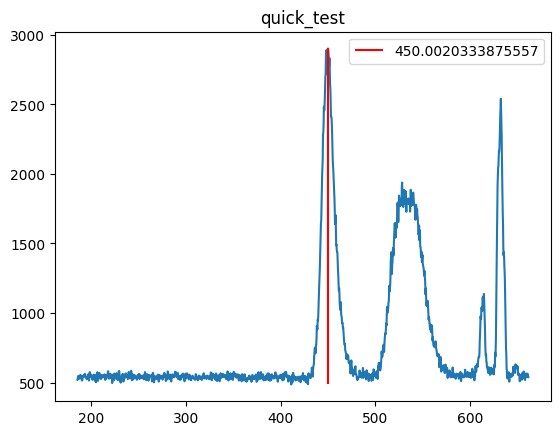

In [110]:
micro_time = 3*1e6
spec.integration_time_micros(micro_time)
nm,ints = spec.spectrum()
plt.plot(nm,ints)
# plt.plot(nm,ints-dark_)
plt.vlines(nm[np.argmax(ints)],np.min(ints),np.max(ints),color='r',label=nm[np.argmax(ints)])
plt.title('quick_test'.format(micro_time/1e3))
# plt.ylim(np.min(ints),np.max(ints))
plt.legend()

In [96]:
fish_dict = {
    'int_t':micro_time, # us
    'spectrum':ints,
    'wavelength':nm,
    'ts':datetime.datetime.now()
}
# np.save('./Jana_JanasLED_575nm.npy',fish_dict)